# Gaussian graphical models: the math grades example

This notebook accompanies the slides *Gaussian graphical models* (Dependence Modeling, Session 2).

We consider the examination marks of $n = 88$ students in $d = 5$ subjects (mechanics, vectors, algebra, analysis, statistics), from the data set `mathmarks` of the R package `bnmonitor`.

**Goal.** Estimate the precision matrix $\hat\Theta = \hat\Sigma^{-1}$ and use its (approximate) zeros to propose a graph:

$$X_i \perp\!\!\!\perp X_j \mid \mathbf{X}_{V\setminus\{i,j\}} \iff \Theta_{ij} = 0 .$$

**Steps.**
1. Load and explore the data
2. Covariance and correlation matrices
3. Precision matrix
4. Partial correlations
5. Rudimentary model selection and the resulting graph

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import networkx as nx

pd.set_option("display.precision", 2)

# Load the data: first try the local copy of the repository, otherwise download it from GitHub
LOCAL_PATH = "../data/mathmarks.csv"
URL = "https://raw.githubusercontent.com/AnasMourahib/Dependence-modeling-/main/data/mathmarks.csv"
try:
    df = pd.read_csv(LOCAL_PATH)
except FileNotFoundError:
    df = pd.read_csv(URL)

# Short names, as on the slides
df.columns = ["mech", "vect", "alg", "analy", "stat"]
n, d = df.shape
print(f"n = {n} students, d = {d} subjects")

n = 88 students, d = 5 subjects


## 1. The data

Each row is a student, each column a subject (marks out of 100).

In [2]:
df.head()

,mech,vect,alg,analy,stat
0,77,82,67,67,81
1,63,78,80,70,81
2,75,73,71,66,81
3,55,72,63,70,68
4,63,63,65,70,63


In [3]:
df.describe().round(1)

,mech,vect,alg,analy,stat
count,88.0,88.0,88.0,88.0,88.0
mean,39.0,50.6,50.6,46.7,42.3
std,17.5,13.1,10.6,14.8,17.3
min,0.0,9.0,15.0,9.0,9.0
25%,30.0,42.0,45.0,35.8,31.0
50%,41.5,51.0,50.0,49.0,40.0
75%,49.2,60.0,57.2,57.0,51.5
max,77.0,82.0,80.0,70.0,81.0


### Pairwise scatterplots

Every pair of subjects is positively associated. The question of a graphical model is different: which pairs are still associated **after conditioning on all other subjects**?

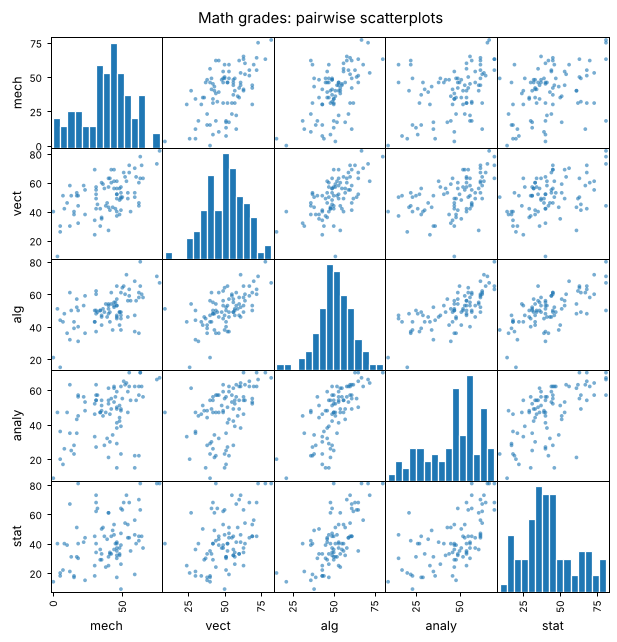

In [4]:
axes = pd.plotting.scatter_matrix(df, figsize=(8, 8), diagonal="hist",
                                  alpha=0.6, hist_kwds={"bins": 15, "edgecolor": "white"})
plt.suptitle("Math grades: pairwise scatterplots", y=0.92)
plt.show()

## 2. Covariance and correlation matrices

We compute the sample covariance matrix $\hat\Sigma$ (with denominator $n-1$, as `np.cov` and R's `cov` do). The correlation matrix is easier to read, since it does not depend on the scale of the marks.

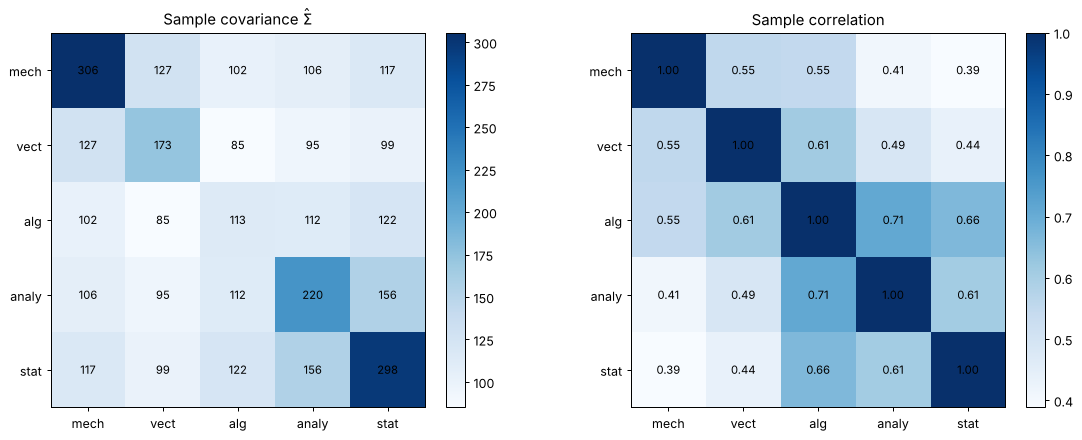

In [5]:
def heatmap(M, title, ax, fmt="{:.2f}", center=None, cmap="RdBu_r", skip_diag=False):
    # Labelled heatmap of a square DataFrame M, with the values written in the cells.
    # skip_diag=True colours only the off-diagonal entries (the diagonal is shown in grey),
    # so that large diagonal values do not dominate the colour scale.
    values = M.to_numpy().astype(float)
    shown = values.copy()
    if skip_diag:
        np.fill_diagonal(shown, np.nan)
    if center is not None:
        bound = np.nanmax(np.abs(shown - center))
        norm = TwoSlopeNorm(vcenter=center, vmin=center - bound, vmax=center + bound)
    else:
        norm = None
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("lightgray")
    im = ax.imshow(np.ma.masked_invalid(shown), cmap=cm, norm=norm)
    ax.set_xticks(range(M.shape[1]), M.columns)
    ax.set_yticks(range(M.shape[0]), M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(round(values[i, j], 2) + 0.0), ha="center", va="center", fontsize=9)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

Sigma_hat = df.cov()          # sample covariance matrix
Corr_hat = df.corr()          # sample correlation matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
heatmap(Sigma_hat, r"Sample covariance $\hat\Sigma$", axes[0], fmt="{:.0f}", cmap="Blues")
heatmap(Corr_hat, "Sample correlation", axes[1], cmap="Blues")
plt.tight_layout()
plt.show()

All correlations are positive and fairly large: from the marginal point of view, **every subject is related to every other subject**.

## 3. Precision matrix

The sample precision matrix is $\hat\Theta = \hat\Sigma^{-1}$. As on the slides, we display it multiplied by $10^3$.

In [6]:
Theta_hat = pd.DataFrame(np.linalg.inv(Sigma_hat), index=df.columns, columns=df.columns)

Theta_display = (Theta_hat * 1e3).round(2)
Theta_display

,mech,vect,alg,analy,stat
mech,5.24,-2.44,-2.74,0.01,-0.14
vect,-2.44,10.43,-4.71,-0.79,-0.17
alg,-2.74,-4.71,26.95,-7.05,-4.70
analy,0.01,-0.79,-7.05,9.88,-2.02
stat,-0.14,-0.17,-4.70,-2.02,6.45


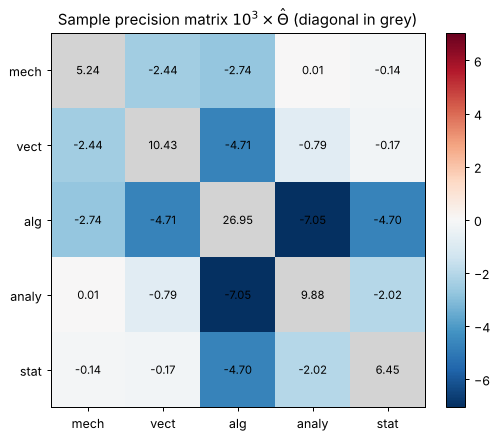

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
heatmap(Theta_hat * 1e3, r"Sample precision matrix $10^{3}\times\hat\Theta$ (diagonal in grey)", ax, center=0, skip_diag=True)
plt.tight_layout()
plt.show()

Some off-diagonal entries are much closer to zero than the others, e.g. (mech, analy), (mech, stat), (vect, analy) and (vect, stat). These are candidates for **missing edges**.

## 4. Partial correlations

The entries of $\hat\Theta$ depend on the scale of the variables, which makes them hard to compare. Rescaling gives the **partial correlations**

$$\rho_{ij\cdot\text{rest}} = -\frac{\Theta_{ij}}{\sqrt{\Theta_{ii}\,\Theta_{jj}}}, \qquad i \neq j,$$

i.e. the correlation between $X_i$ and $X_j$ after removing the linear effect of all the other variables. In a Gaussian model, $\rho_{ij\cdot\text{rest}} = 0 \iff \Theta_{ij} = 0 \iff X_i \perp\!\!\!\perp X_j \mid \mathbf{X}_{V\setminus\{i,j\}}$.

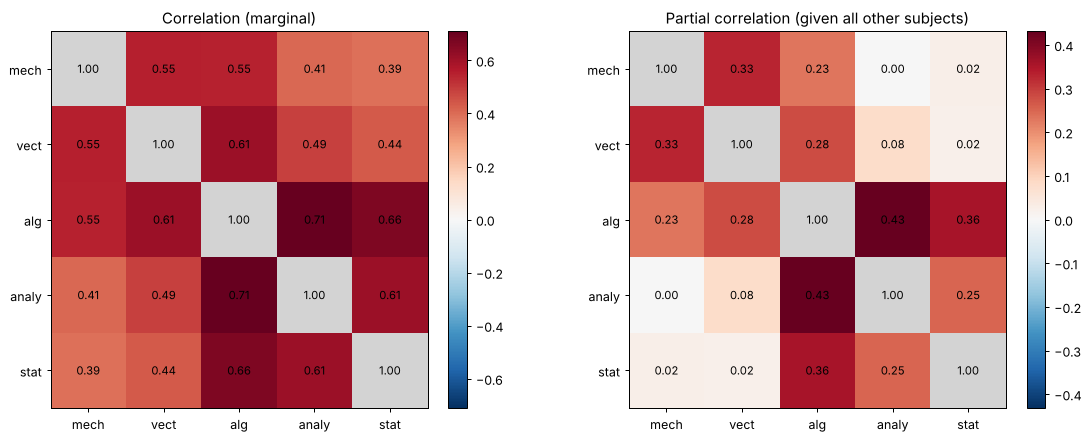

In [8]:
T = Theta_hat.to_numpy()
D = np.sqrt(np.diag(T))
P = -T / np.outer(D, D)
np.fill_diagonal(P, 1.0)
Partial = pd.DataFrame(P, index=df.columns, columns=df.columns)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
heatmap(Corr_hat, "Correlation (marginal)", axes[0], center=0, skip_diag=True)
heatmap(Partial, "Partial correlation (given all other subjects)", axes[1], center=0, skip_diag=True)
plt.tight_layout()
plt.show()

Compare the two panels: the marginal correlations are all large, but several partial correlations are close to zero. Conditioning on the other subjects removes most of the dependence between, e.g., mechanics and analysis.

## 5. Rudimentary model selection

As on the slides, we treat every off-diagonal entry with $|\hat\Theta_{ij}| < 10^{-3}$ as evidence for $\Theta_{ij} = 0$, i.e. for a **missing edge**. (A principled way of selecting the zeros, the graphical lasso, is the topic of the next session.)

In [9]:
threshold = 1e-3

rows = []
names = list(df.columns)
for i in range(d):
    for j in range(i + 1, d):
        theta_ij = Theta_hat.iloc[i, j]
        rows.append({
            "pair": f"{names[i]} - {names[j]}",
            "10^3 x Theta_ij": round(theta_ij * 1e3, 2),
            "partial corr": round(Partial.iloc[i, j], 2) + 0.0,
            "edge?": "yes" if abs(theta_ij) >= threshold else "no",
        })
edges_table = pd.DataFrame(rows).sort_values("10^3 x Theta_ij", key=np.abs, ascending=False)
edges_table.reset_index(drop=True)

,pair,10^3 x Theta_ij,partial corr,edge?
0,alg - analy,-7.05,0.43,yes
1,vect - alg,-4.71,0.28,yes
2,alg - stat,-4.70,0.36,yes
3,mech - alg,-2.74,0.23,yes
4,mech - vect,-2.44,0.33,yes
5,analy - stat,-2.02,0.25,yes
6,vect - analy,-0.79,0.08,no
7,vect - stat,-0.17,0.02,no
8,mech - stat,-0.14,0.02,no
9,mech - analy,0.01,0.00,no


### The resulting graph

Keeping only the pairs with $|\hat\Theta_{ij}| \ge 10^{-3}$ gives the **butterfly graph** of the slides: a model with 5 diagonal and 6 off-diagonal parameters, i.e. 11 parameters instead of 15. Edge widths are proportional to the absolute partial correlation.

Missing edges: ['mech - analy', 'mech - stat', 'vect - analy', 'vect - stat']


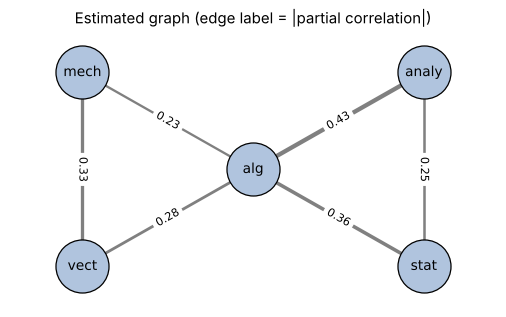

In [10]:
G = nx.Graph()
G.add_nodes_from(names)
for i in range(d):
    for j in range(i + 1, d):
        if abs(Theta_hat.iloc[i, j]) >= threshold:
            G.add_edge(names[i], names[j], weight=abs(Partial.iloc[i, j]))

# Same layout as on the slides: algebra in the middle
pos = {"mech": (0, 1), "vect": (0, -1), "alg": (2, 0), "analy": (4, 1), "stat": (4, -1)}

fig, ax = plt.subplots(figsize=(7, 4))
widths = [8 * G[u][v]["weight"] for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=widths, edge_color="gray", ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=1800, node_color="lightsteelblue", edgecolors="black", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=11, ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{G[u][v]['weight']:.2f}" for u, v in G.edges()},
                             font_size=9, ax=ax)
ax.set_title("Estimated graph (edge label = |partial correlation|)")
ax.margins(0.15)
ax.axis("off")
plt.show()

missing = [f"{names[i]} - {names[j]}" for i in range(d) for j in range(i + 1, d) if not G.has_edge(names[i], names[j])]
print("Missing edges:", missing)

## Questions

1. Which conditional independencies does the butterfly graph encode, according to the **pairwise** Markov property?
2. Using the **global** Markov property, which set of subjects separates $\{\text{mech}, \text{vect}\}$ from $\{\text{analy}, \text{stat}\}$? Interpret this in terms of the marks.
3. Change the threshold (e.g. to $5\cdot 10^{-4}$ or $2\cdot 10^{-3}$). How does the graph change? Why is a fixed threshold not a satisfactory way to select a model?